In [2]:
%load_ext autoreload
%autoreload 2
%reload_ext autoreload


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
"""
Fluence data analysis script

This script loads fluence and temperature data for further analysis.
"""

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
from importlib import reload

import fluence_lib
from fluence_lib import (
    load_avg_fluence,
    load_temperature_data,
    prepare_sensor_data,
    simulate_current_sensor,
    plot_leakage_current
)

# Global constants
KB = 8.617333262145e-5  # Boltzmann constant in eV/K
T_REF = 294.15  # Reference temperature in K (20°C)
E_I_STAR = 1.30  # Activation energy in eV
# Default parameters
ALPHA_I = 1.23e-17  # A/cm
ALPHA_0_STAR = 7.07e-17  # A/cm
BETA = 3.29e-18 # A/cm
E_I = 1.11 # eV
K_0I = 1.2e13 #1/s
T_0 = 1.0 #min
V=4.0 #cm3

class Parameters:
    """
    Class to store physical parameters used in calculations.
    """
    def __init__(self):
        # Set initial values from global constants
        self.E_I_star = E_I_STAR
        self.kb = KB  # Add Boltzmann constant
        self.T_ref = T_REF
        self.k_0I = K_0I
        self.E_I = E_I
        self.alpha_I = ALPHA_I
        self.alpha_0_star = ALPHA_0_STAR
        self.beta = BETA
        self.t_0 = T_0
        self.V = V

    def get_kb(self) -> float:
        """Get Boltzmann constant in eV/K"""
        return self.kb

    def get_E_I_star(self) -> float:
        """Get activation energy in eV"""
        return self.E_I_star
    def set_E_I_star(self, value: float):
        self.E_I_star = value
        
    def set_T_ref(self, value: float):
        self.T_ref = value
        
    def set_k_0I(self, value: float):
        self.k_0I = value
        
    def set_E_I(self, value: float):
        self.E_I = value
        
    def set_alpha_I(self, value: float):
        self.alpha_I = value
        
    def set_alpha_0_star(self, value: float):
        self.alpha_0_star = value
        
    def set_beta(self, value: float):
        self.beta = value
        
    def set_t_0(self, value: float):
        self.t_0 = value
    
    def set_V(self, value: float):
        self.V = value


In [24]:
def load_data():
    """
    Load both fluence and temperature data.
    """
    fluence_file = os.path.join('in_data', 'avgFluenceBinned.csv')
    temp_file = os.path.join('in_data', 'run2_temp_A_60s.csv')
    
    fluence_df = load_avg_fluence(fluence_file)
    print("Fluence data loaded successfully!")
    
    temp_df = load_temperature_data(temp_file)
    print("Temperature data loaded successfully!")
    
    return fluence_df, temp_df

def test_single_sensor(fluence_df: pd.DataFrame, temp_df: pd.DataFrame, params):
    """
    Test current simulation for a single sensor.
    """
    sensor_name = 'VL01_CT'  # Example sensor
    
    # Prepare data for this sensor
    fdf,tdf = fluence_lib.prepare_sensor_data(fluence_df, temp_df, sensor_name)

    current_df = []
    # Simulate current for this sensor
    current_df = fluence_lib.simulate_current_sensor(fdf,tdf, params)
    
    return current_df

In [25]:

import fluence_lib

reload(fluence_lib)
params = Parameters()
    
# Load data
fluence_df, temp_df = load_data()
    
# Test for a single sensor
df = test_single_sensor(fluence_df, temp_df, params)

Fluence data loaded successfully!


/home/maria/magisterka/hamburg_new/fluence_lib.py:74: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  fluence_series = fluence_series.reindex(pd.date_range(fluence_series.index.min(), fluence_series.index.max(), freq='10T'), fill_value=0)


Temperature data loaded successfully!
Starting current simulation...
Calculating time factors...
Starting main calculation loop...


 68%|██████▊   | 100064/148086 [01:32<01:29, 538.16it/s]

100000


100%|██████████| 148086/148086 [03:11<00:00, 774.66it/s]

Simulation completed!


## TEST: Function to recalculate temperature

In [ ]:
#   Reading current sample data
import fluence_lib

reload(fluence_lib)
params = Parameters()

current_sample_file = os.path.join('in_data', 'run2_current_sample.csv')
current_sample_df = pd.read_csv(current_sample_file)
current_sample_df['TS'] = pd.to_datetime(current_sample_df['TS'])  # Convert TS to datetime
current_sample_df.set_index('TS', inplace=True)
current_adjusted = fluence_lib.adjust_current_with_temperature(current_sample_df, temp_df, params,'VL02_CT')


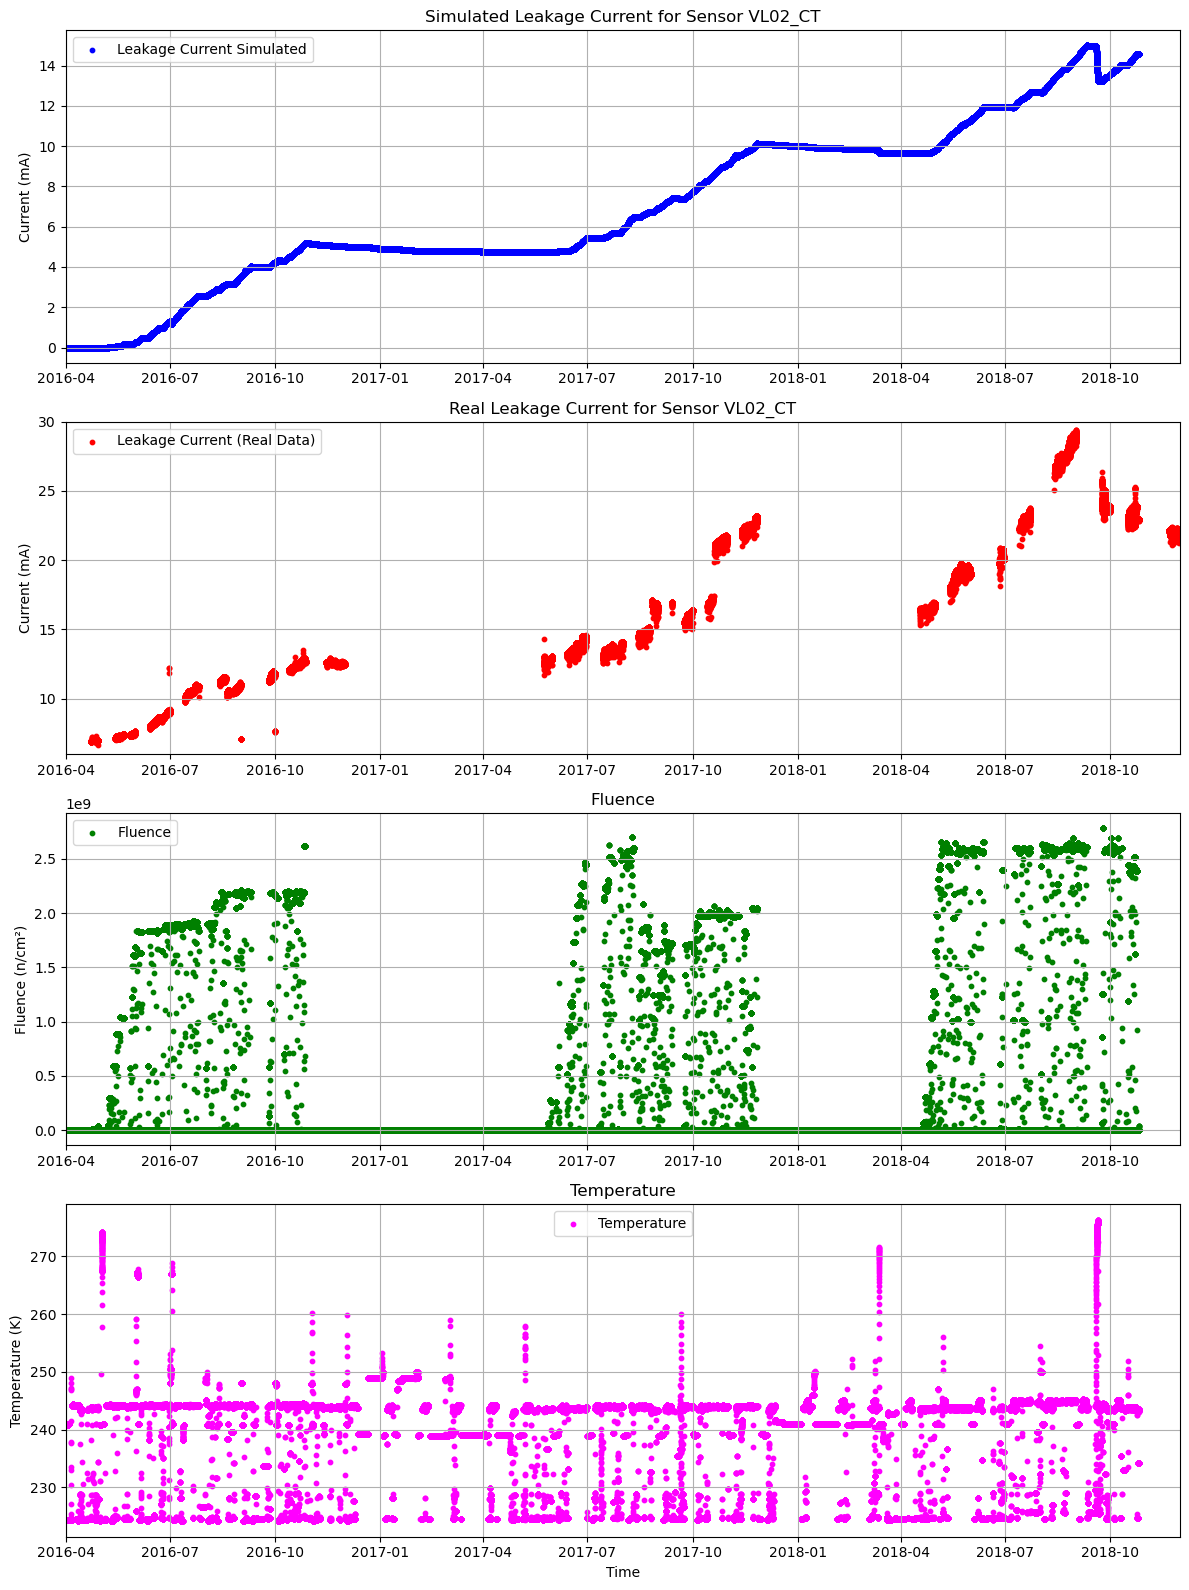

In [34]:
fluence_lib.plot_leakage_current(df, current_adjusted,'VL02_CT')